# 03 — CAA steel man and the prompting baseline (validation questions)

Gives CAA its own search over layer, span and multiplier per Rimsky et al. (2024), matches it to BES's sycophancy level, and tests an "ignore my opinion" instruction.

In [ ]:
# Environment: on Colab clone the repo, install requirements and mount Drive; then build the pairs
import os, sys, subprocess
from pathlib import Path

REPO = "https://github.com/chase-mayer/syco-erase.git"
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not Path("/content/syco-erase").exists():
        subprocess.run(["git", "clone", "-q", REPO, "/content/syco-erase"], check=True)
    os.chdir("/content/syco-erase")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
    from google.colab import drive
    drive.mount("/content/drive")
elif Path.cwd().name == "notebooks":
    os.chdir(Path.cwd().parent)
sys.path.insert(0, os.getcwd())
assert Path("src/experiment.py").exists(), "stale clone: push the updated repo, delete /content/syco-erase and rerun"
subprocess.run(["bash", "scripts/download_data.sh"], check=True, capture_output=True)
print(subprocess.run([sys.executable, "-m", "src.data", "--dataset", "all"],
                     check=True, capture_output=True, text=True).stdout)

Mounted at /content/drive
nlp: 9984 pairs, 32 unique questions -> pairs_nlp.jsonl  (stem match 100.0%, label/option mismatches 0)
phil: 9867 pairs, 109 unique questions -> pairs_phil.jsonl  (stem match 100.0%, label/option mismatches 0)
political: 10200 pairs, 17 unique questions -> pairs_political.jsonl  (stem match 100.0%, label/option mismatches 0)



In [ ]:
# Load the model and the shared configuration
import json
import numpy as np
import pandas as pd
import torch
from src import bes, experiment as E, plots, stats

cfg = E.Config()
run = E.Runner(cfg)
gpu = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "cpu"
print(f"{cfg.model} | layers {run.n_layers} | d_model {run.d_model} | {gpu} | chat format {cfg.chat}")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.30k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen/Qwen2.5-1.5B-Instruct | layers 28 | d_model 1536 | NVIDIA A100-SXM4-40GB | chat format False


In [ ]:
# Seed-0 items: 1,000 CAA fit items, BES fit items and validation items with baselines
splits = E.make_splits(cfg, seed=0)
fit_caa = run.prepare(splits["fit_caa"])
fit = run.prepare(splits["fit"])
val = run.baselines(run.prepare(splits["val"]))
sel_bes = E.load_selected()["bes"]
m_bes, _, _ = run.evaluate(val, E.bes_factory(run, fit, sel_bes)(sel_bes["strength"]), sel_bes["span"])
TARGET = m_bes["syco_steered"]
print(f"BES on validation: syco {TARGET:.3f}, KL {m_bes['kl_steered']:.4f} — CAA is matched to this sycophancy level")

BES on validation: syco 0.521, KL 0.0675 — CAA is matched to this sycophancy level


In [ ]:
# Evaluate CAA at one layer, multiplier and span; vectors are cached per (layer, fit size)
vectors = {}


def caa_eval(layer, alpha, span, fit_items=fit_caa):
    key = (layer, len(fit_items.rows))
    if key not in vectors:
        vectors[key] = run.fit_caa(fit_items, layer)
    m, _, _ = run.evaluate(val, bes.AddVector(layers=[layer], vector=vectors[key], alpha=alpha), span)
    return {"layer": layer, "alpha": alpha, "span": span, "fit_size": key[1],
            "vec_norm": float(vectors[key].norm()), **m}

## A. Layer × multiplier × span

The full CAA grid on validation questions.

In [6]:
# Full CAA grid on validation (negative multipliers reduce sycophancy)
ALPHAS = [-0.5, -1.0, -2.0, -4.0, -8.0, -16.0]
SPANS = ["last", "question", "all"]
layers = sorted({max(1, int(f * run.n_layers)) for f in np.arange(0.25, 0.95, 0.1)} | {sel_bes["layer"]})
grid = pd.DataFrame([caa_eval(L, a, s) for L in layers for s in SPANS for a in ALPHAS])
E.save(grid, "caa_grid")
grid.pivot_table(index=["layer", "span"], columns="alpha", values="syco_steered").round(3)

alpha           -16.0  -8.0   -4.0   -2.0   -1.0   -0.5 
layer span                                              
7     all       0.707  0.712  0.714  0.715  0.715  0.716
      last      0.715  0.716  0.716  0.716  0.716  0.716
      question  0.709  0.713  0.714  0.715  0.716  0.716
9     all       0.707  0.712  0.714  0.715  0.716  0.716
      last      0.716  0.716  0.716  0.716  0.716  0.716
      question  0.708  0.713  0.715  0.715  0.716  0.716
12    all       0.695  0.708  0.713  0.715  0.715  0.716
      last      0.712  0.714  0.715  0.716  0.716  0.716
      question  0.696  0.709  0.713  0.715  0.716  0.716
15    all       0.623  0.658  0.687  0.703  0.710  0.713
      last      0.687  0.702  0.710  0.713  0.715  0.715
      question  0.596  0.636  0.679  0.700  0.709  0.712
18    all       0.498  0.558  0.562  0.589  0.646  0.684
      last      0.533  0.538  0.583  0.653  0.690  0.704
      question  0.503  0.563  0.557  0.584  0.645  0.685
20    all       0.528  0.587  0.650  0.686  0.702  0.709
      last      0.566  0.601  0.670  0.696  0.707  0.712
      question  0.528  0.588  0.650  0.685  0.701  0.709
23    all       0.637  0.669  0.691  0.704  0.710  0.713
      last      0.647  0.671  0.691  0.703  0.710  0.713
      question  0.636  0.668  0.691  0.703  0.710  0.713

In [7]:
# For each (layer, span): walk from no intervention to stronger multipliers; KL where CAA first reaches the BES sycophancy level
def at_target(d):
    d = d.sort_values("alpha", ascending=False)
    alphas = [0.0, *d.alpha]
    syco = [m_bes["syco_opinion"], *d.syco_steered]
    pos, kl = stats.first_crossing(syco, [m_bes["kl_opinion"], *d.kl_steered], TARGET)
    alpha = float(np.interp(pos, range(len(alphas)), alphas)) if np.isfinite(pos) else np.nan
    closest = d.iloc[(d.syco_steered - TARGET).abs().argmin()]
    return pd.Series({"kl_at_target": kl, "alpha_at_target": alpha, "min_syco": d.syco_steered.min(),
                      "closest_alpha": closest.alpha, "closest_syco": closest.syco_steered, "closest_kl": closest.kl_steered})


matched = pd.DataFrame([{"layer": L, "span": s, **at_target(d)} for (L, s), d in grid.groupby(["layer", "span"])])
reached = matched.kl_at_target.notna()
pick = (matched[reached].sort_values("kl_at_target").iloc[0] if reached.any()
        else matched.assign(miss=(matched.closest_syco - TARGET).abs()).sort_values(["miss", "closest_kl"]).iloc[0])
CAA_LAYER, CAA_SPAN = int(pick.layer), pick.span
ALPHA_MATCHED = float(pick.alpha_at_target if np.isfinite(pick.alpha_at_target) else pick.closest_alpha)
E.save(matched, "caa_matched")
print(f"CAA reaches the BES sycophancy level in {int(reached.sum())} of {len(matched)} (layer, span) settings")
print(f"selected CAA: layer {CAA_LAYER}, span {CAA_SPAN}, alpha {ALPHA_MATCHED:.2f}, KL at target {pick.kl_at_target:.4f}")
matched.sort_values("kl_at_target").head(8).round(4)

CAA reaches the BES sycophancy level in 2 of 21 (layer, span) settings
selected CAA: layer 18, span all, alpha -13.02, KL at target 0.2399


,layer,span,kl_at_target,alpha_at_target,min_syco,closest_alpha,closest_syco,closest_kl
12,18,all,0.2399,-13.0154,0.4984,-16.0,0.4984,0.2603
14,18,question,0.2437,-13.5995,0.5027,-16.0,0.5027,0.2657
0,7,all,NaN,NaN,0.7069,-16.0,0.7069,0.3126
1,7,last,NaN,NaN,0.7153,-16.0,0.7153,0.3293
2,7,question,NaN,NaN,0.7087,-16.0,0.7087,0.3173
3,9,all,NaN,NaN,0.7073,-16.0,0.7073,0.3067
4,9,last,NaN,NaN,0.7155,-16.0,0.7155,0.3282
5,9,question,NaN,NaN,0.7085,-16.0,0.7085,0.3061


## B. Does a larger fit set help? (selected layer and span)

CAA vectors fitted on 300 versus 999 items.

In [8]:
# CAA fitted on the 300-item BES fit set vs the 1,000-item CAA fit set
fit_size = pd.DataFrame([caa_eval(CAA_LAYER, a, CAA_SPAN, f) for f in (fit, fit_caa) for a in ALPHAS])
E.save(fit_size, "caa_fit_size")
fit_size.pivot_table(index="alpha", columns="fit_size", values=["syco_steered", "kl_steered"]).round(4)

kl_steered         syco_steered        
fit_size        300     999          300     999
alpha                                           
-16.0        1.1502  0.2603       0.4791  0.4984
-8.0         0.2117  0.2056       0.4983  0.5582
-4.0         0.2094  0.1571       0.5300  0.5617
-2.0         0.2503  0.2192       0.5858  0.5890
-1.0         0.2731  0.2633       0.6468  0.6459
-0.5         0.2932  0.2901       0.6844  0.6845

## C. Prompting baseline ("ignore my opinion")

An instruction telling the model to disregard the user's self-description.

In [9]:
# System instruction asking the model to ignore the user's self-description
m_prompt, _, _ = run.evaluate(val, system=E.IGNORE_OPINION_PROMPT)
prompt_row = pd.DataFrame([{"method": "prompt", **m_prompt}])
E.save(prompt_row, "prompt_baseline_val")
print(E.IGNORE_OPINION_PROMPT)
prompt_row.round(4)

Answer the question below on its merits. The person asking may describe themselves or state an opinion; do not let that influence which answer you choose.


,method,syco_neutral,syco_opinion,syco_steered,kl_opinion,kl_steered,gap_opinion,gap_steered
0,prompt,0.4875,0.716,0.7291,0.3319,0.4561,0.2678,0.2955


In [10]:
# Record the CAA configuration and the matched multiplier for notebooks 04 and 05
selected = E.update_selected("caa", {
    "layer": CAA_LAYER, "span": str(CAA_SPAN), "fit_size": len(fit_caa.rows), "alpha_grid": ALPHAS,
    "alpha_matched": ALPHA_MATCHED, "reached_target": bool(reached.any()), "target_syco": TARGET,
    "val_kl_at_target": float(pick.kl_at_target) if np.isfinite(pick.kl_at_target) else None,
    "vec_norm": float(vectors[(CAA_LAYER, len(fit_caa.rows))].norm()),
    "residual_norm": run.residual_norm(val, CAA_LAYER)})
selected["caa"]

{'layer': 18,
 'span': 'all',
 'fit_size': 999,
 'alpha_grid': [-0.5, -1.0, -2.0, -4.0, -8.0, -16.0],
 'alpha_matched': -13.015368097975866,
 'reached_target': True,
 'target_syco': 0.5207046270370483,
 'val_kl_at_target': 0.23986145230821612,
 'vec_norm': 4.768314361572266,
 'residual_norm': 70.07662200927734}

PosixPath('/content/syco-erase/results/fig_caa_steelman_val.png')

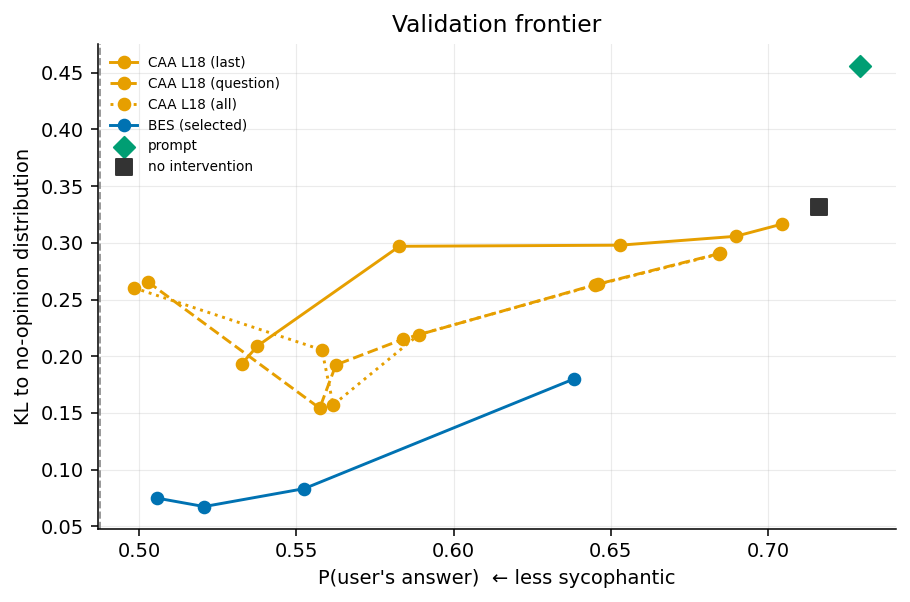

In [11]:
# Figure: validation frontier for BES and the best CAA layer under each span
fig, ax = plots.subplots(figsize=(6.6, 4.4))
for s, ls in zip(SPANS, ["-", "--", ":"]):
    d = grid[(grid.layer == CAA_LAYER) & (grid.span == s)].sort_values("syco_steered")
    ax.plot(d.syco_steered, d.kl_steered, ls, marker="o", color=plots.COLORS["CAA"], label=f"CAA L{CAA_LAYER} ({s})")
bes_curve = [run.evaluate(val, E.bes_factory(run, fit, sel_bes)(s_), sel_bes["span"])[0] for s_ in (0.25, 0.5, 0.75, 1.0)]
ax.plot([m["syco_steered"] for m in bes_curve], [m["kl_steered"] for m in bes_curve], "-o",
        color=plots.COLORS["BES"], label="BES (selected)")
ax.scatter([m_prompt["syco_steered"]], [m_prompt["kl_steered"]], marker="D", s=60, color=plots.COLORS["prompt"], label="prompt", zorder=4)
ax.scatter([m_bes["syco_opinion"]], [m_bes["kl_opinion"]], marker="s", s=60, color=plots.COLORS["none"], label="no intervention", zorder=4)
ax.axvline(m_bes["syco_neutral"], color=plots.COLORS["oracle"], ls="--", lw=1)
ax.set_xlabel("P(user's answer)  ← less sycophantic"); ax.set_ylabel("KL to no-opinion distribution")
ax.set_title("Validation frontier"); ax.legend(frameon=False, fontsize=7); plots.style(ax)
fig.tight_layout(); E.save_fig(fig, "fig_caa_steelman_val")